# Walkthrough: adaptive load balancing study

This notebook reads the results committed in `results/`, shows the headline numbers and reruns a few
simulations to look at the dynamics behind them. Six policies are compared: RR, WRR, LC, P2C, LRT and
the proposed ASED. Everything here can be regenerated with `python -m lbsim run all` and
`python -m lbsim analyze`.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lbsim import simulate, summarize, get_scenario
from lbsim.metrics import windows
from lbsim.policies import LABELS
from lbsim.stats import mean_ci

pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)
runs = pd.read_csv("../results/main/runs.csv")
print(runs.shape, "runs,", runs.seed.nunique(), "seeds,", runs.scenario.nunique(), "scenarios")

(720, 45) runs, 20 seeds, 6 scenarios


## 1. The simulator against queueing theory

Each case was run with 10 seeds; the analytic value should fall inside the 95% interval.

In [2]:
val = pd.read_csv("../results/validation/validation_runs.csv")
rows = []
for case, g in val.groupby("case", sort=False):
    m, h = mean_ci(g.value)
    a = g.analytic.iloc[0]
    rows.append(dict(case=case, analytic=a, simulated=m, ci=h, rel_error=(m - a) / a * 100, covered=abs(m - a) <= h))
pd.DataFrame(rows)

,case,analytic,simulated,ci,rel_error,covered
0,M/M/1 rho=0.5,2.000,2.004,0.036,0.180,True
1,M/M/1 rho=0.8,5.000,4.976,0.238,-0.481,True
2,M/M/4 rho=0.8,1.746,1.743,0.027,-0.162,True
3,M/D/1 rho=0.7,2.167,2.166,0.025,-0.048,True
4,M/G/1 lognormal cv=1.5 rho=0.6,3.438,3.482,0.136,1.309,True
5,M/M/1/5 rho=0.9 (blocking),0.126,0.127,0.003,0.624,True
6,"4 x M/M/1, random split, rho=0.7",3.333,3.320,0.042,-0.389,True
7,M/M/4 rho=0.8 (utilization),0.800,0.799,0.003,-0.105,True


## 2. Main comparison

Mean over 20 seeds. All policies in a scenario replay the same traces, so the comparison is paired.

In [3]:
order = list(LABELS)
scen = ["baseline", "heterogeneous", "bursty", "flash_crowd", "server_crash", "gray_failure"]
p99 = runs.pivot_table(index="policy", columns="scenario", values="p99").loc[order, scen] * 1000
mean = runs.pivot_table(index="policy", columns="scenario", values="mean").loc[order, scen] * 1000
print("P99 (ms)")
print(p99.round(0))
print()
print("mean (ms)")
print(mean.round(1))

P99 (ms)
scenario  baseline  heterogeneous  bursty  flash_crowd  server_crash  gray_failure
policy                                                                            
rr           266.0         1523.0  2175.0       1569.0        1572.0        3042.0
wrr          266.0          597.0  1545.0        863.0         981.0        3014.0
lc           236.0          449.0  1099.0        863.0         495.0         549.0
p2c          247.0          744.0  1556.0        992.0        1025.0        1514.0
lrt          237.0          349.0   901.0        727.0         374.0         414.0
ased         239.0          355.0   834.0        676.0         368.0         409.0

mean (ms)
scenario  baseline  heterogeneous  bursty  flash_crowd  server_crash  gray_failure
policy                                                                            
rr            67.1          263.9   311.4        310.2         299.1         447.9
wrr           67.1           85.5   219.2        113.6         124.

In [4]:
ranks = pd.read_csv("../results/tables/ranks.csv")
overall = ranks[ranks.scenario == "all"].pivot(index="policy", columns="metric", values="rank")
print(overall.sort_values("p99").round(2))
print(open("../results/tables/friedman.txt").read())

metric  mean   p99
policy            
ased    1.53  1.65
lrt     2.05  1.68
lc      2.42  2.79
wrr     4.53  4.47
p2c     4.53  4.55
rr      5.92  5.86
p99: Friedman chi2=508.2, p=1.34e-107, blocks=120, k=6, Nemenyi CD=0.69
mean: Friedman chi2=519.2, p=5.84e-110, blocks=120, k=6, Nemenyi CD=0.69



## 3. ASED against the two strongest baselines

LRT and LC have the next-best mean ranks. Ratio = other / ASED (above 1 favours ASED), Wilcoxon
signed-rank test with Holm correction.

In [5]:
pw = pd.read_csv("../results/tables/pairwise_ased.csv")
sel = pw[pw.policy.isin(["lrt", "lc"]) & (pw.metric == "p99")]
sel[["group", "policy", "ratio", "ratio_lo", "ratio_hi", "p_holm", "ref_wins"]]

,group,policy,ratio,ratio_lo,ratio_hi,p_holm,ref_wins
1,baseline,lc,0.986,0.984,0.987,5.722e-05,0.00
4,baseline,lrt,0.990,0.988,0.992,5.722e-05,0.05
16,heterogeneous,lc,1.263,1.255,1.271,5.722e-05,1.00
19,heterogeneous,lrt,0.982,0.976,0.988,5.722e-05,0.05
31,bursty,lc,1.346,1.253,1.445,5.722e-05,0.95
34,bursty,lrt,1.097,1.043,1.155,1.116e-02,0.75
46,flash_crowd,lc,1.285,1.216,1.358,5.722e-05,1.00
49,flash_crowd,lrt,1.078,1.045,1.112,1.289e-03,0.85
61,server_crash,lc,1.344,1.326,1.363,5.722e-05,1.00
64,server_crash,lrt,1.015,1.007,1.023,2.123e-03,0.80


## 4. One run up close: two servers crash

Seed 0 of the crash scenario. A crashed server refuses connections, so its in-flight count drops to zero
and least-loaded rules keep choosing it until the health checker removes it.

In [6]:
sc = get_scenario("server_crash")
trace = sc.trace(0)
res = {}
for p in ["wrr", "lc", "lrt", "ased"]:
    res[p] = simulate(sc, p, 0, trace)
    row = summarize(res[p], sc)
    print(f"{LABELS[p]:5s} errors during outage {row['failure_errors']:5d}   P99 {row['p99'] * 1000:6.0f} ms   mean {row['mean'] * 1000:5.1f} ms")

WRR   errors during outage   324   P99    989 ms   mean 125.6 ms


LC    errors during outage   547   P99    484 ms   mean  81.6 ms


LRT   errors during outage  1122   P99    378 ms   mean  62.9 ms


ASED  errors during outage    72   P99    372 ms   mean  60.6 ms


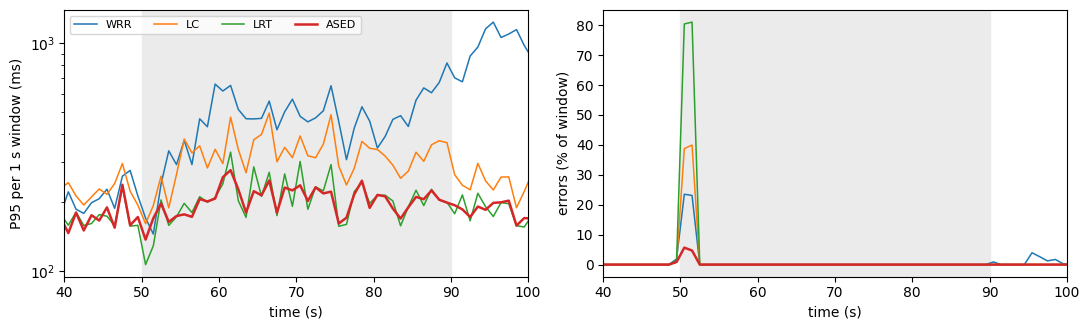

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for p, r in res.items():
    w = windows(r, sc)
    ax[0].plot(w.start + 0.5, w.p95 * 1000, lw=1.8 if p == "ased" else 1.1, label=LABELS[p])
    ax[1].plot(w.start + 0.5, w.err_frac * 100, lw=1.8 if p == "ased" else 1.1, label=LABELS[p])
for a in ax:
    a.axvspan(50, 90, color="0.92")
    a.set_xlim(40, 100)
    a.set_xlabel("time (s)")
ax[0].set_yscale("log")
ax[0].set_ylabel("P95 per 1 s window (ms)")
ax[1].set_ylabel("errors (% of window)")
ax[0].legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

## 5. Gray failure: configured weights against learned speeds

Servers 5, 6 and 10 run at 30% speed between 50 s and 90 s. WRR keeps sending them their configured
share, LC and LRT react to queues and latency, and ASED sees the longer processing times in the responses.

In [8]:
sc = get_scenario("gray_failure")
trace = sc.trace(0)
for p in ["wrr", "lc", "lrt", "ased"]:
    r = simulate(sc, p, 0, trace)
    during = (r.times >= 55) & (r.times < 90)
    share = np.bincount(r.server[during], minlength=12) / during.sum()
    print(f"{LABELS[p]:5s} share of requests sent to the slowed servers: {share[[5, 6, 10]].sum() * 100:4.1f}%"
          f"   P99 {summarize(r, sc)['p99'] * 1000:5.0f} ms")
print("capacity share of those servers after the slowdown:", round(0.3 * 15.2 / (48 - 0.7 * 15.2) * 100, 1), "%")

WRR   share of requests sent to the slowed servers: 31.7%   P99  2925 ms


LC    share of requests sent to the slowed servers: 12.9%   P99   560 ms


LRT   share of requests sent to the slowed servers:  8.3%   P99   422 ms


ASED  share of requests sent to the slowed servers:  9.7%   P99   412 ms
capacity share of those servers after the slowdown: 12.2 %


## 6. Sensitivity to the number of balancer replicas

Each replica only sees its own requests. Local counts lose information as the number of replicas grows.

In [9]:
sens = pd.read_csv("../results/tables/sensitivity_summary.csv")
d = sens[sens.sweep == "dispatchers"].pivot(index="policy", columns="x", values="p99") * 1000
d.loc[["rr", "wrr", "lc", "p2c", "lrt", "ased"]].round(0)

x,1.0,2.0,4.0,8.0,16.0
policy,,,,,
rr,1560.0,1546.0,1558.0,1545.0,1522.0
wrr,622.0,607.0,586.0,629.0,587.0
lc,402.0,420.0,452.0,506.0,696.0
p2c,521.0,618.0,739.0,954.0,1241.0
lrt,363.0,356.0,351.0,347.0,347.0
ased,335.0,339.0,356.0,347.0,369.0


## Summary

* ASED and LRT form the top group on P99 (the Nemenyi test cannot separate them); ASED has the best
  mean rank on mean latency.
* Static weights (WRR) fix heterogeneity only while the configuration is right; when servers slow down
  silently, WRR keeps feeding them.
* Fast-failing crashes turn least-loaded rules (LC, LRT) into black holes unless errors are taken into
  account.
* Local information degrades with many balancer replicas, most for P2C and LC.

The README discusses the trade-offs and limitations in detail.